<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/computer-vision/Image_Compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import pywt
import os
import warnings
warnings.filterwarnings("ignore")
from google.colab.patches import cv2_imshow
from matplotlib import pyplot as plt
import numpy as np

The image height and width: (250, 300)
The input image in4599  bytes
Original image


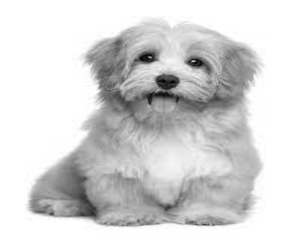

Threshold 10 Output Image in 19404 bytes     compression ratio 0.24:1


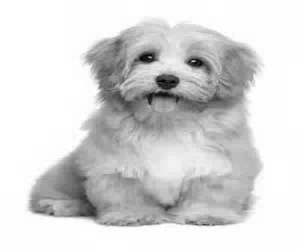

Threshold 50 Output Image in 12583 bytes     compression ratio 0.37:1


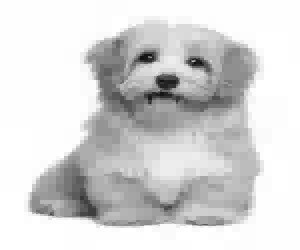

Threshold 100 Output Image in 9721 bytes     compression ratio 0.47:1


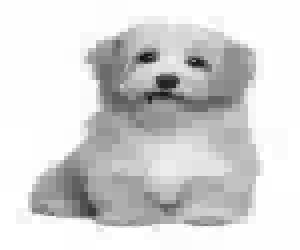

Threshold 200 Output Image in 7681 bytes     compression ratio 0.6:1


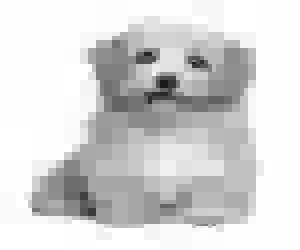

<Figure size 720x720 with 0 Axes>

In [ ]:
input_path="/content/dog1.jpg"
img = cv2.imread(input_path,0)
img=cv2.resize(img,(300,250))
print(f"The image height and width: {img.shape}")
input_image_bytes=round((os.stat(input_path).st_size),7)
print(f"The input image in{input_image_bytes}  bytes")
print(f"Original image")
cv2_imshow(img)
keep=[10,50,100,200]
coeffs = pywt.wavedecn(img, wavelet='haar', level=8)
arr, coeff_slices = pywt.coeffs_to_array(coeffs)
plt.figure(figsize=(10,10))
for thresh in keep:
  L=len(np.where(abs(arr)<=thresh)[0])
  arr[np.where(abs(arr)<=thresh)]=0
  arr = np.round(arr)
  coeffs_from_arr = pywt.array_to_coeffs(arr, coeff_slices,output_format='wavedecn')#db4
  img1_recon = pywt.waverecn(coeffs_from_arr, wavelet='haar')
  result=np.vstack((img1_recon))
  output_path="output_image.png"
  cv2.imwrite(output_path,img1_recon)
  output_image_bytes=round((os.stat(output_path).st_size),4)
  com_ratio=input_image_bytes/output_image_bytes
  comp_ratio=round(com_ratio,4)
  print(f"Threshold {thresh} Output Image in {output_image_bytes} bytes     compression ratio {round(input_image_bytes/output_image_bytes,2)}:1")
  cv2_imshow(result)